# So sánh Dataset V2 và V3 trên V1 - C4 - seed 44

Notebook này **không huấn luyện lại model**. Nó đọc trực tiếp các artifact hiện hành của Phase 2 để trả lời hai câu hỏi:

1. Khi giữ nguyên kiến trúc V1, cấu hình C4 và seed 44, việc loại Playback khỏi tập học ảnh hưởng thế nào trên **Common Raw Test**?
2. Hai model phản ứng thế nào trên tập **Playback-only** bị loại khỏi V3?

Quy ước nhãn: `0 = Asthma`, `1 = Non-Asthma`. Ngưỡng phân loại: `p_non_asthma >= 0.5`. Test chỉ dùng để đánh giá sau huấn luyện.

Thiết kế này là một phép **ablation theo dataset**: V2 và V3 dùng cùng frontend C4, cùng kiến trúc V1 và cùng seed 44; biến chính được khảo sát là sự hiện diện của 160 bản Playback. Vì vậy, chênh lệch quan sát được có thể được diễn giải theo hướng tác động của thành phần Playback, trong giới hạn của một lần train.

In [9]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.titleweight': 'bold'})

def find_phase2_dir():
    cwd = Path.cwd().resolve()
    for base in (cwd, *cwd.parents):
        for candidate in (
            base,
            base / 'AI_Training_Model' / 'Phase2_Preprocess_&_Traning',
        ):
            marker = candidate / 'Output_Comparison_V2_1_vs_V3_1' / 'metrics_summary.csv'
            if marker.is_file():
                return candidate
    raise FileNotFoundError('Không tìm thấy Phase2 hoặc metrics_summary.csv.')

PHASE2 = find_phase2_dir()
RESULTS = PHASE2 / 'Output_Comparison_V2_1_vs_V3_1'
FIG_DIR = RESULTS
print('Phase 2:', PHASE2)
print('Kết quả so sánh:', RESULTS)

Phase 2: D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\Phase2_Preprocess_&_Traning
Kết quả so sánh: D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\Phase2_Preprocess_&_Traning\Output_Comparison_V2_1_vs_V3_1


## 1. Thành phần Dataset V2 và V3

Số lượng được đọc từ chính `Y_<split>_mel.npy` và `Files_<split>.npy`, không ghi cứng trong notebook.

Mục này xác nhận V3 được tạo từ V2 bằng cách loại Playback, nhưng vẫn giữ Asthma augmentation và các clip Environment. Nhờ đó ta tránh hiểu nhầm V3 là một dataset được chia hoặc tăng cường lại từ đầu.

In [10]:
feature_dirs = {
    'V2 - có Playback': PHASE2 / 'Output_Preprocess',
    'V3 - không Playback': PHASE2 / 'Output_Preprocess_V3_No_Playback',
}
dataset_rows = []
for dataset_name, feature_dir in feature_dirs.items():
    for split in ('train', 'val', 'test'):
        labels = np.load(feature_dir / f'Y_{split}_mel.npy').astype(int)
        files = np.load(feature_dir / f'Files_{split}.npy', allow_pickle=False).astype(str)
        playback = np.char.find(np.char.lower(files), '__take') >= 0
        dataset_rows.append({
            'dataset': dataset_name,
            'split': split,
            'Asthma': int((labels == 0).sum()),
            'Non-Asthma': int((labels == 1).sum()),
            'Playback': int(playback.sum()),
            'Tổng': int(len(labels)),
        })
dataset_summary = pd.DataFrame(dataset_rows)
display(dataset_summary)

,dataset,split,Asthma,Non-Asthma,Playback,Tổng
0,V2 - có Playback,train,987,987,128,1974
1,V2 - có Playback,val,38,116,16,154
2,V2 - có Playback,test,38,121,16,159
3,V3 - không Playback,train,923,923,0,1846
4,V3 - không Playback,val,30,108,0,138
5,V3 - không Playback,test,30,113,0,143


## 2. Kiểm tra hợp đồng thí nghiệm

Hai model chỉ được so sánh trực tiếp khi cùng kiến trúc, cấu hình C4, seed và kích thước tensor.

Bảng audit đọc `Training_Metadata.json` của từng lần train và kiểm tra cả config SHA-256. Nếu một điều kiện không khớp, notebook dừng bằng `assert` thay vì tiếp tục tạo một phép so sánh không công bằng.

In [11]:
v2_meta_path = PHASE2 / 'Output_Train_V1_SepConv2D_Flatten' / 'Training_Metadata.json'
v3_meta_path = PHASE2 / 'Output_Train_V3_V1_No_Playback' / 'Training_Metadata.json'
comparison_meta_path = RESULTS / 'comparison_metadata.json'

v2_meta = json.loads(v2_meta_path.read_text(encoding='utf-8'))
v3_meta = json.loads(v3_meta_path.read_text(encoding='utf-8'))
comparison_meta = json.loads(comparison_meta_path.read_text(encoding='utf-8'))

audit = pd.DataFrame([
    {
        'Model': 'V2 - có Playback',
        'Architecture': v2_meta['architecture'],
        'Cấu hình': v2_meta['variant_id'],
        'Config SHA-256': v2_meta['config_sha256'],
        'Seed': v2_meta['seed'],
        'Input': ' x '.join(map(str, v2_meta['input_shape'])),
        'Parameters': v2_meta['parameter_count'],
        'Epoch tốt nhất': v2_meta['best_epoch'],
    },
    {
        'Model': 'V3 - không Playback',
        'Architecture': v3_meta['architecture'],
        'Cấu hình': v3_meta['frontend_variant_id'],
        'Config SHA-256': v3_meta['frontend_config_sha256'],
        'Seed': v3_meta['seed'],
        'Input': ' x '.join(map(str, v3_meta['input_shape'])),
        'Parameters': v3_meta['parameter_count'],
        'Epoch tốt nhất': v3_meta['best_epoch_by_val_loss'],
    },
])
display(audit)

assert audit['Architecture'].nunique() == 1, 'Hai model khác kiến trúc.'
assert audit['Config SHA-256'].nunique() == 1, 'Hai model khác cấu hình frontend.'
assert audit['Seed'].nunique() == 1, 'Hai model khác seed.'
assert audit['Input'].nunique() == 1, 'Hai model khác tensor đầu vào.'
print('PASS: Hai model cùng V1, C4, seed 44 và tensor 40 x 129 x 1.')

,Model,Architecture,Cấu hình,Config SHA-256,Seed,Input,Parameters,Epoch tốt nhất
0,V2 - có Playback,V1_SepConv2D_Flatten,combo_pre0_mel40_fft2048,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,44,40 x 129 x 1,331386,27
1,V3 - không Playback,V1_SepConv2D_Flatten,combo_pre0_mel40_fft2048,5ae8a2c91c92b58653d899ddec056485787b6307db2cc0...,44,40 x 129 x 1,331386,14


PASS: Hai model cùng V1, C4, seed 44 và tensor 40 x 129 x 1.


## 3. Chỉ số trên Common Raw và Playback-only

`Common Raw` là phép so sánh chính vì cả hai model đi qua đúng cùng 143 mẫu raw. `Playback-only` là phép kiểm tra miền bổ sung, không dùng để thay thế kết luận trên Common Raw.

Ngoài Accuracy, cần ưu tiên Asthma Recall và Asthma F1 vì bỏ sót một mẫu Asthma có ý nghĩa khác với phân loại nhầm Non-Asthma. Các chỉ số được trình bày đồng thời để tránh kết luận chỉ từ một giá trị Accuracy.

In [12]:
metrics = pd.read_csv(RESULTS / 'metrics_summary.csv')
metric_columns = [
    'accuracy', 'asthma_precision', 'asthma_recall', 'asthma_f1',
    'non_asthma_precision', 'non_asthma_recall', 'non_asthma_f1',
]
metrics_display = metrics[['test_name', 'model', 'sample_count', *metric_columns]].copy()
metrics_display[metric_columns] = metrics_display[metric_columns].mul(100).round(2)
display(metrics_display.rename(columns={
    'test_name': 'Test', 'model': 'Model', 'sample_count': 'N',
    'accuracy': 'Accuracy (%)',
    'asthma_precision': 'Asthma Precision (%)',
    'asthma_recall': 'Asthma Recall (%)',
    'asthma_f1': 'Asthma F1 (%)',
    'non_asthma_precision': 'Non-Asthma Precision (%)',
    'non_asthma_recall': 'Non-Asthma Recall (%)',
    'non_asthma_f1': 'Non-Asthma F1 (%)',
}))

,Test,Model,N,Accuracy (%),Asthma Precision (%),Asthma Recall (%),Asthma F1 (%),Non-Asthma Precision (%),Non-Asthma Recall (%),Non-Asthma F1 (%)
0,common_raw,V2_1_With_Playback,143,92.31,78.79,86.67,82.54,96.36,93.81,95.07
1,common_raw,V3_1_No_Playback,143,90.21,72.22,86.67,78.79,96.26,91.15,93.64
2,playback_only,V2_1_With_Playback,16,75.00,100.00,50.00,66.67,66.67,100.00,80.00
3,playback_only,V3_1_No_Playback,16,87.50,100.00,75.00,85.71,80.00,100.00,88.89


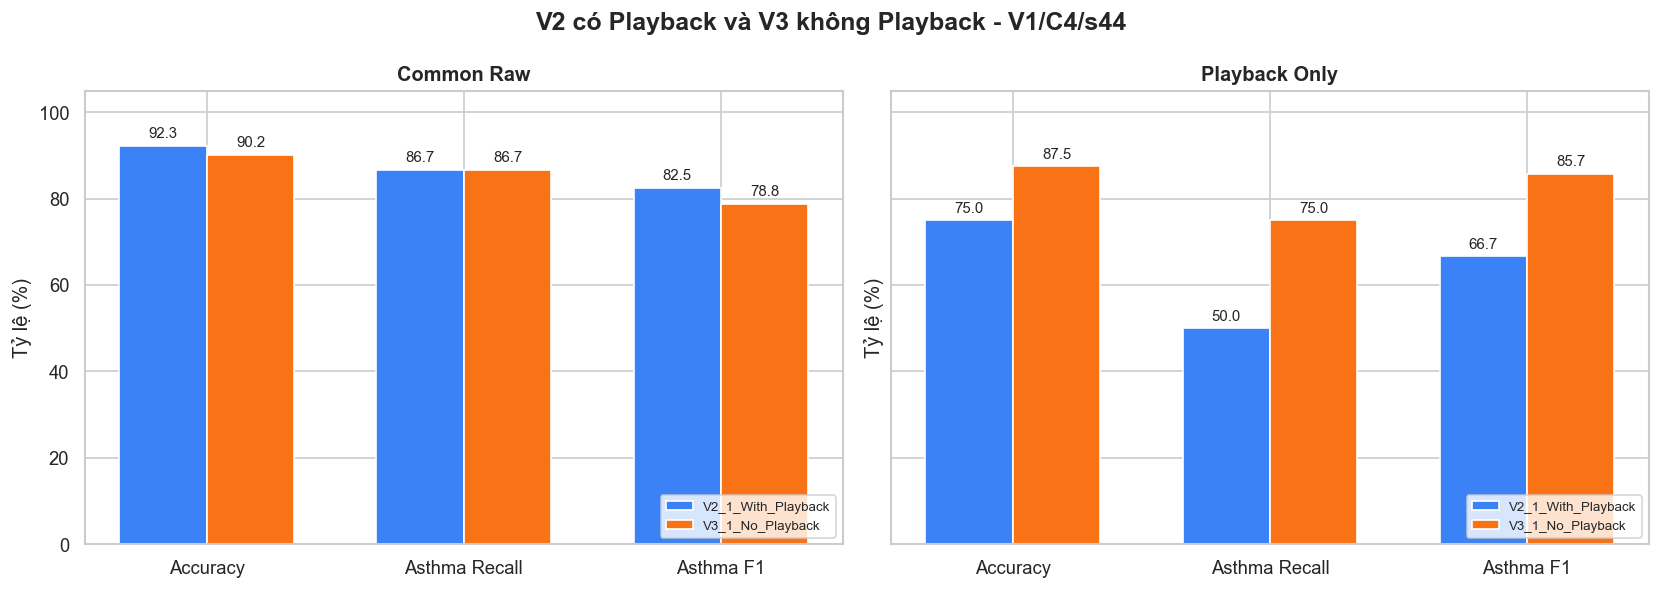

In [13]:
plot_metrics = ['accuracy', 'asthma_recall', 'asthma_f1']
pretty = {'accuracy': 'Accuracy', 'asthma_recall': 'Asthma Recall', 'asthma_f1': 'Asthma F1'}
colors = ['#3B82F6', '#F97316']
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, test_name in zip(axes, ['common_raw', 'playback_only']):
    subset = metrics[metrics['test_name'].eq(test_name)].set_index('model')
    x = np.arange(len(plot_metrics))
    width = 0.34
    for idx, model_name in enumerate(subset.index):
        values = subset.loc[model_name, plot_metrics].to_numpy(float) * 100
        bars = ax.bar(x + (idx - 0.5) * width, values, width, label=model_name, color=colors[idx])
        ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
    ax.set_xticks(x, [pretty[m] for m in plot_metrics])
    ax.set_ylim(0, 105)
    ax.set_title(test_name.replace('_', ' ').title())
    ax.set_ylabel('Tỷ lệ (%)')
    ax.legend(fontsize=8, loc='lower right')
fig.suptitle('V2 có Playback và V3 không Playback - V1/C4/s44', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_v2_v3_metric_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Ma trận nhầm lẫn

Ma trận nhầm lẫn cho biết cụ thể lỗi đến từ Asthma hay Non-Asthma. Hàng là nhãn thật, cột là nhãn dự đoán; thứ tự cố định `[Asthma, Non-Asthma]`.

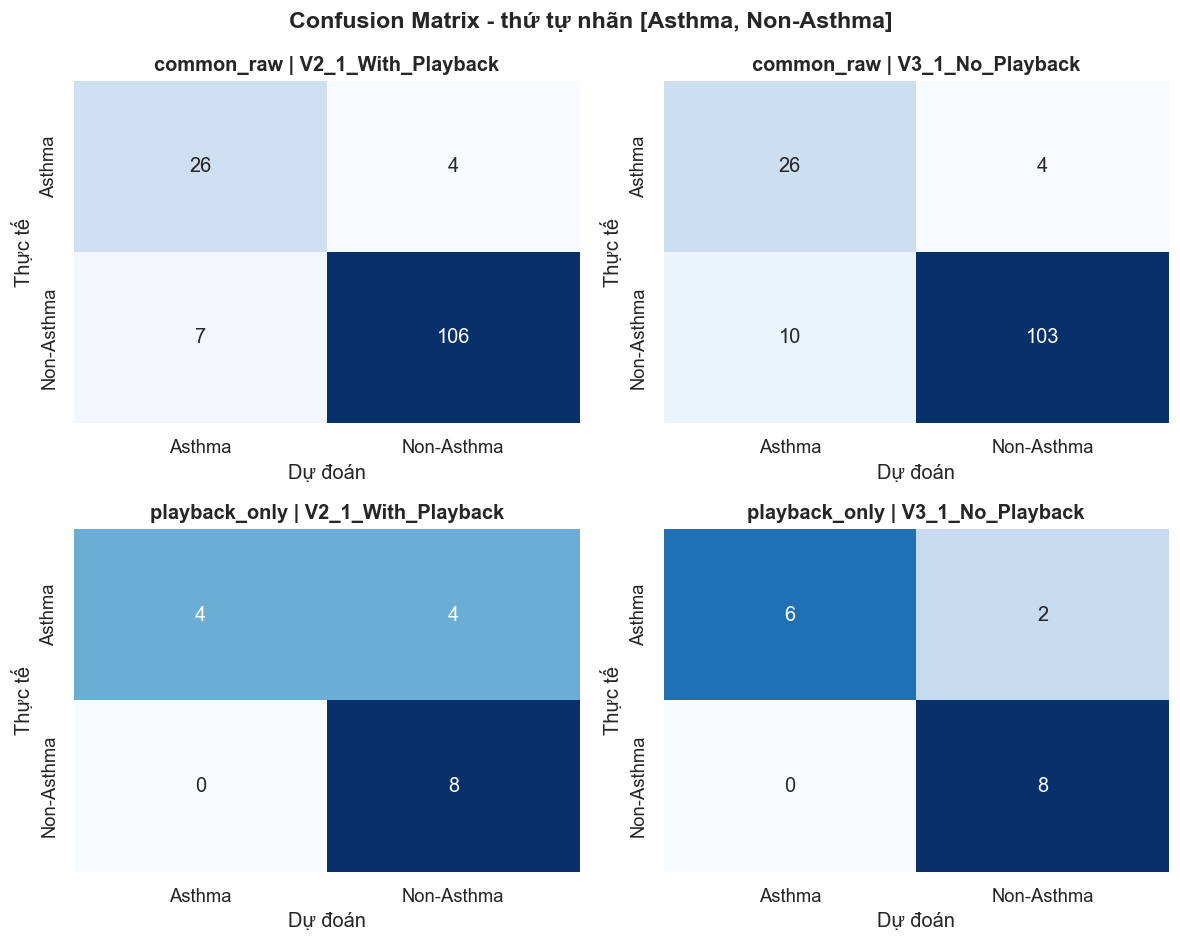

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (_, row) in zip(axes.flat, metrics.iterrows()):
    cm = np.array([
        [row['true_asthma_pred_asthma'], row['true_asthma_pred_non_asthma']],
        [row['true_non_asthma_pred_asthma'], row['true_non_asthma_pred_non_asthma']],
    ], dtype=int)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Asthma', 'Non-Asthma'],
                yticklabels=['Asthma', 'Non-Asthma'])
    ax.set_title(f"{row['test_name']} | {row['model']}")
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')
fig.suptitle('Confusion Matrix - thứ tự nhãn [Asthma, Non-Asthma]', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_v2_v3_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Phân bố xác suất `p_non_asthma`

Điểm gần 0 nghiêng về Asthma; điểm gần 1 nghiêng về Non-Asthma.

Biểu đồ này bổ sung thông tin mà Accuracy không thể hiện: model có dự đoán chắc chắn hay tập trung nhiều mẫu quanh ngưỡng 0.5. Những mẫu sát ngưỡng có nguy cơ đổi nhãn khi tín hiệu đi qua loa, microphone hoặc lượng tử hóa.

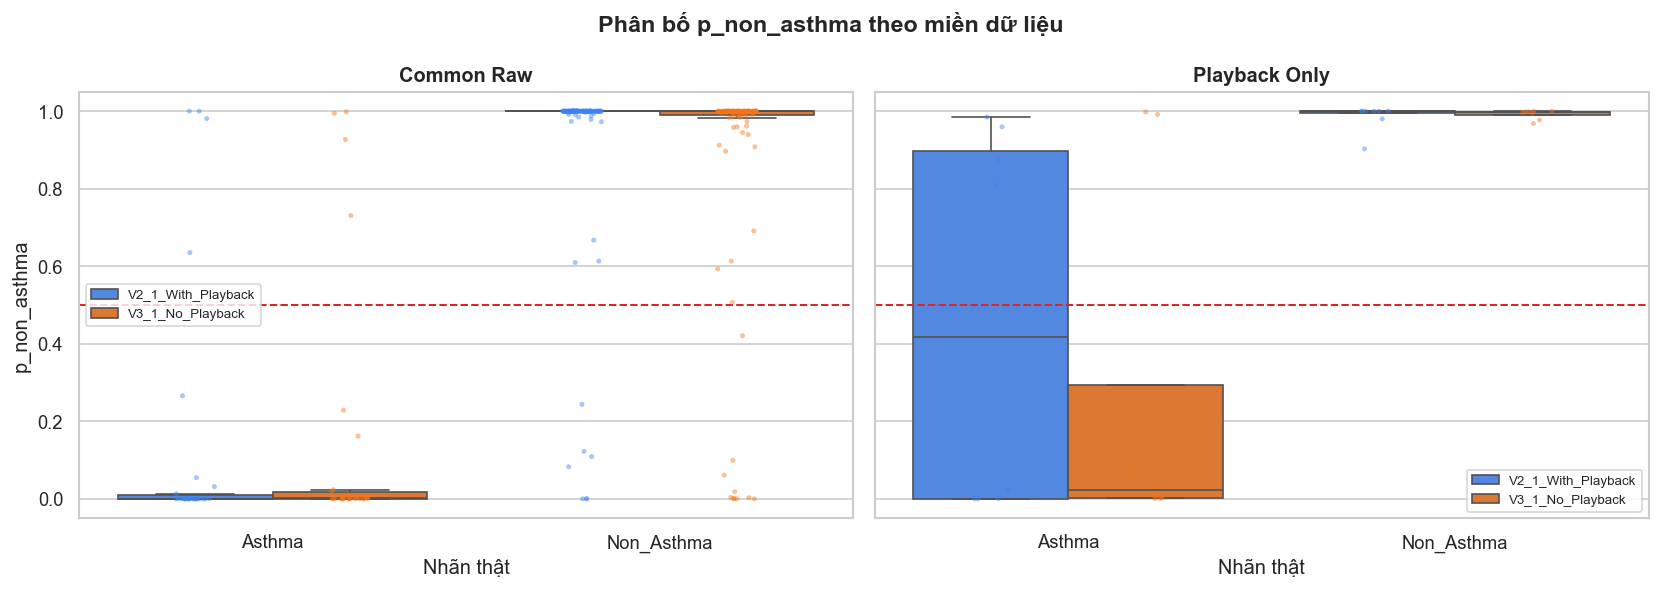

In [15]:
prediction_frames = []
for test_name, file_name in [
    ('common_raw', 'common_raw_predictions.csv'),
    ('playback_only', 'playback_only_predictions.csv'),
]:
    frame = pd.read_csv(RESULTS / file_name)
    long = frame.melt(
        id_vars=['file', 'true_class'],
        value_vars=['model_a_p_non_asthma', 'model_b_p_non_asthma'],
        var_name='model_key', value_name='p_non_asthma',
    )
    long['model'] = long['model_key'].map({
        'model_a_p_non_asthma': comparison_meta['model_a_name'],
        'model_b_p_non_asthma': comparison_meta['model_b_name'],
    })
    long['test_name'] = test_name
    prediction_frames.append(long)
prediction_long = pd.concat(prediction_frames, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, test_name in zip(axes, ['common_raw', 'playback_only']):
    subset = prediction_long[prediction_long['test_name'].eq(test_name)]
    sns.boxplot(data=subset, x='true_class', y='p_non_asthma', hue='model',
                palette=colors, showfliers=False, ax=ax)
    sns.stripplot(data=subset, x='true_class', y='p_non_asthma', hue='model',
                  dodge=True, alpha=0.45, size=3, palette=colors, legend=False, ax=ax)
    ax.axhline(0.5, color='#DC2626', linestyle='--', linewidth=1.2, label='Threshold 0.5')
    ax.set_title(test_name.replace('_', ' ').title())
    ax.set_xlabel('Nhãn thật')
    ax.set_ylabel('p_non_asthma')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:2], labels[:2], fontsize=8, loc='best')
fig.suptitle('Phân bố p_non_asthma theo miền dữ liệu', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'notebook_v2_v3_p_non_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Kết luận tự động từ artifact hiện hành

Cell dưới đây tính trực tiếp độ chênh từ CSV hiện hành, nhờ đó kết luận số học tự cập nhật nếu hai model được train và đánh giá lại.

In [16]:
def metric_value(test_name, model_name, column):
    row = metrics[metrics['test_name'].eq(test_name) & metrics['model'].eq(model_name)]
    return float(row.iloc[0][column])

model_a = comparison_meta['model_a_name']
model_b = comparison_meta['model_b_name']
common_delta = 100 * (metric_value('common_raw', model_b, 'accuracy') - metric_value('common_raw', model_a, 'accuracy'))
playback_delta = 100 * (metric_value('playback_only', model_b, 'accuracy') - metric_value('playback_only', model_a, 'accuracy'))
recall_delta = 100 * (metric_value('common_raw', model_b, 'asthma_recall') - metric_value('common_raw', model_a, 'asthma_recall'))

display(Markdown(f'''
- Trên **Common Raw Test**, V3 trừ V2 về Accuracy là **{common_delta:+.2f} điểm phần trăm**.
- Chênh lệch Asthma Recall trên Common Raw là **{recall_delta:+.2f} điểm phần trăm**.
- Trên **Playback-only**, V3 trừ V2 về Accuracy là **{playback_delta:+.2f} điểm phần trăm**.
- Kết luận chính phải ưu tiên Common Raw vì đây là tập chung và độc lập cho cả hai model.
- Kết quả Playback-only cho biết phản ứng miền loa → INMP441, nhưng không tự nó chứng minh Playback nên được thêm hoặc loại khỏi tập học.

**Model SHA-256**

- V2: `{comparison_meta['model_a_sha256']}`
- V3: `{comparison_meta['model_b_sha256']}`
'''))


- Trên **Common Raw Test**, V3 trừ V2 về Accuracy là **-2.10 điểm phần trăm**.
- Chênh lệch Asthma Recall trên Common Raw là **+0.00 điểm phần trăm**.
- Trên **Playback-only**, V3 trừ V2 về Accuracy là **+12.50 điểm phần trăm**.
- Kết luận chính phải ưu tiên Common Raw vì đây là tập chung và độc lập cho cả hai model.
- Kết quả Playback-only cho biết phản ứng miền loa → INMP441, nhưng không tự nó chứng minh Playback nên được thêm hoặc loại khỏi tập học.

**Model SHA-256**

- V2: `2af2fcd110f26b58c5dc0805426865b4cc7e24f4f9208a08158c269be20f6768`
- V3: `d1aed5f8bdc424c1eb3b96b32ac5340a330445dab06bf38c56b39f674dbaea22`


## 7. Kết luận nghiên cứu và quyết định sử dụng Playback

Trên phép so sánh chính **Common Raw Test**, model V2 có Playback đạt **92,31% Accuracy**, cao hơn model V3 không Playback đạt **90,21%**. Hai model cùng đạt **86,67% Asthma Recall**, nhưng V2 có Asthma Precision và Asthma F1 cao hơn; đồng thời số Non-Asthma bị dự đoán nhầm thành Asthma giảm từ **10 xuống 7**. Kết quả này cho thấy việc giữ Playback trong tập huấn luyện không làm suy giảm khả năng nhận biết Asthma trên raw test, mà còn cải thiện độ chính xác tổng thể và giảm false positive trên tập chung.

Trên Playback-only, V3 đạt 87,50% còn V2 đạt 75,00%. Kết quả này nhắc rằng Playback không tự động bảo đảm model sẽ tốt hơn trên mọi mẫu thu lại; hiệu quả còn phụ thuộc file, loa, khoảng cách và đáp ứng microphone. Vì vậy Playback-only được xem là phân tích miền bổ sung, không phải tiêu chí duy nhất để chọn dataset.

**Quyết định:** giữ Playback trong pipeline huấn luyện V2. Lý do là V2 bao phủ thêm miền loa → INMP441 và đạt kết quả tốt hơn trên Common Raw - phép đánh giá công bằng và được ưu tiên. Nói chính xác về mặt nghiên cứu, thí nghiệm này **cung cấp bằng chứng ủng hộ** việc dùng Playback trong cấu hình V1/C4/s44; chưa nên gọi là chứng minh tuyệt đối cho mọi seed hoặc mọi điều kiện phần cứng. Muốn củng cố kết luận, cần lặp lại V2/V3 trên nhiều seed và báo cáo trung bình cùng độ lệch chuẩn.